# Analyze SMETANA and SteadyCom results

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns

# SMETANA

In [ ]:
ecoli_detailed = pd.read_csv("../output/Guillen2021/smetana/_detailed.tsv",sep="\t")
ecoli_global = pd.read_csv("../output/Guillen2021/smetana/_global.tsv",sep="\t")

gut_detailed = pd.read_csv("../output/Venturelli2018/smetana/_detailed.tsv",sep="\t")
gut_global = pd.read_csv("../output/Venturelli2018/smetana/_global.tsv",sep="\t")

### E.coli mutants

In [ ]:
ecoli_global

,community,medium,size,mip,mro
0,ecoli_auxotrophs,complete,7,2,0.586207


**Dependency on metabolite**

In [ ]:
ecoli_detailed[["receiver","compound","mus"]].drop_duplicates().sort_values(by="mus",ascending=False)

,receiver,compound,mus
11,mutant_icd,M_gthrd_e,0.89
8,mutant_icd,M_g3pg_e,0.40
88,mutant_cysW,M_g3pg_e,0.39
87,mutant_cysW,M_g3pe_e,0.37
81,mutant_cysW,M_cys__L_e,0.37
90,mutant_cysW,M_gthrd_e,0.35
10,mutant_icd,M_glyc3p_e,0.31
79,mutant_cysW,M_cgly_e,0.28
7,mutant_icd,M_g3pe_e,0.27
3,mutant_icd,M_fe3dcit_e,0.24


**Dependency on member**

In [ ]:
ecoli_detailed[["receiver","donor","scs"]].drop_duplicates().sort_values(by="scs",ascending=False)

,receiver,donor,scs
0,mutant_icd,mutant_panZ,0.166667
13,mutant_icd,mutant_bioF,0.166667
26,mutant_icd,mutant_bioC,0.166667
39,mutant_icd,mutant_bioH,0.166667
52,mutant_icd,mutant_cysW,0.166667
65,mutant_icd,mutant_panD,0.166667
78,mutant_cysW,mutant_panZ,0.166667
91,mutant_cysW,mutant_bioF,0.166667
104,mutant_cysW,mutant_bioC,0.166667
117,mutant_cysW,mutant_icd,0.166667


### E.coli mutants

In [ ]:
gut_global

,community,medium,size,mip,mro
0,BH-,complete,11,25,0.620264
1,BO-,complete,11,26,0.629661
2,BT-,complete,11,25,0.632174
3,BU-,complete,11,26,0.629536
4,BV-,complete,11,26,0.624561
5,CA-,complete,11,24,0.632287
6,CH-,complete,11,20,0.644545
7,DP-,complete,11,23,0.634632
8,EL-,complete,11,23,0.667273
9,ER-,complete,11,22,0.635345


**Dependency on metabolite**

In [ ]:
gut_detailed_met = gut_detailed[["community","receiver","compound","mus"]].drop_duplicates().sort_values(by="mus",ascending=False)
gut_detailed_met

,community,receiver,compound,mus
181,BO-,Eubacterium_rectale_ATCC_33656,M_rbflvrd__91__e__93__,0.90
90,BH-,Eubacterium_rectale_ATCC_33656,M_rbflvrd__91__e__93__,0.90
683,CH-,Eubacterium_rectale_ATCC_33656,M_rbflvrd__91__e__93__,0.89
455,BV-,Eubacterium_rectale_ATCC_33656,M_rbflvrd__91__e__93__,0.89
1174,PC-,Eubacterium_rectale_ATCC_33656,M_rbflvrd__91__e__93__,0.82
...,...,...,...,...
580,CH-,Bacteroides_uniformis_ATCC_8492,M_h2__91__e__93__,0.01
581,CH-,Bacteroides_uniformis_ATCC_8492,M_lac_D__91__e__93__,0.01
582,CH-,Bacteroides_uniformis_ATCC_8492,M_nchlphncl__91__e__93__,0.01
1,BH-,Bacteroides_uniformis_ATCC_8492,M_ac__91__e__93__,0.01


In [ ]:
gut_detailed_met = gut_detailed_met[gut_detailed_met.mus>0.1]

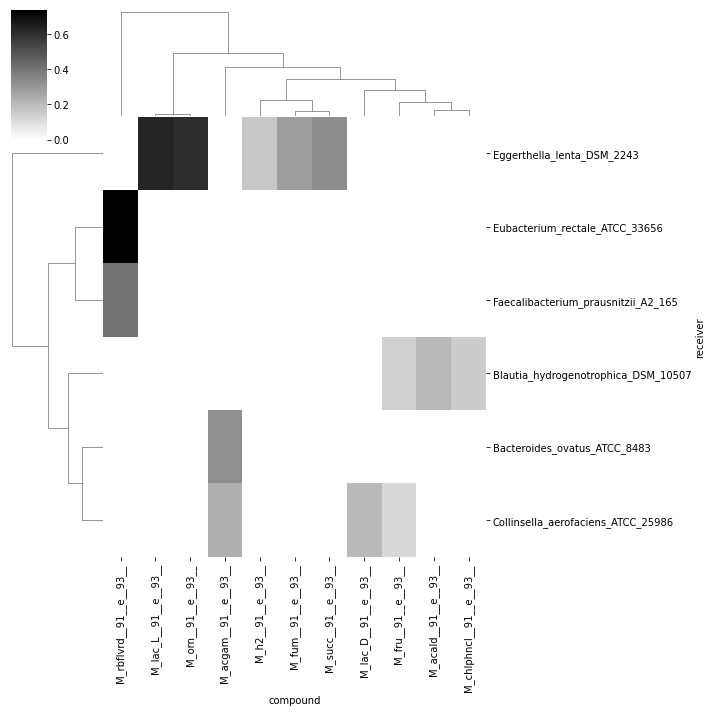

In [ ]:
gut_detailed_met_plot = gut_detailed_met[["receiver","compound","mus"]].groupby(["receiver","compound"]).mean()["mus"].unstack().fillna(0)

sns.clustermap(gut_detailed_met_plot,cmap="binary")

**Dependency on member**

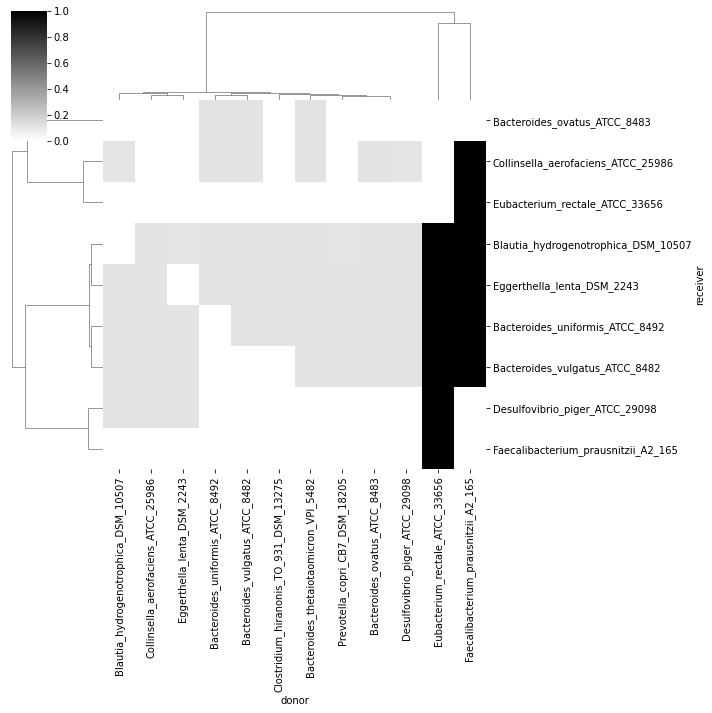

In [ ]:
gut_detailed_member = gut_detailed[["community","receiver","donor","scs"]].drop_duplicates().sort_values(by=["receiver","donor"],ascending=False)

#gut_detailed_member = gut_detailed_member[gut_detailed_member.scs>0.1]

gut_detailed_member_plot = gut_detailed_member[["receiver","donor","scs"]].groupby(["receiver","donor"]).mean()["scs"].unstack().fillna(0)

sns.clustermap(gut_detailed_member_plot,
               cmap="binary")

In [ ]:
import matplotlib as mpl

colors_hex = ["#b69cfd", "#832522", "#86d7a9", "#d725a3", "#11e38c", "#f82f65", "#2e9568", "#d67381", "#20d8fd", "#6c096a", "#b9b9b9", "#0a433b", "#68affc"]
from matplotlib.colors import ListedColormap


cmap = ListedColormap(colors_hex)

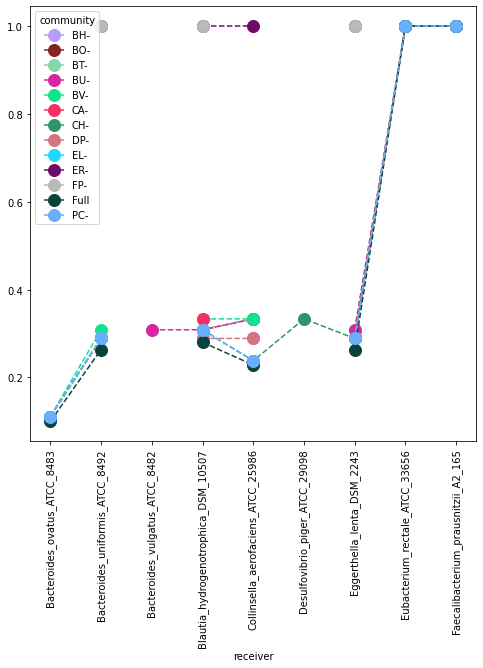

In [ ]:
gut_detailed_member_plot = gut_detailed_member[["community","receiver","scs"]].groupby(["community","receiver"]).mean()["scs"]\
                    .unstack()\
                    .sort_index().T\
                    #.fillna(0)
                    

ax = gut_detailed_member_plot.plot(rot=90,
                                  figsize=(8,8),
                                  cmap =cmap,
                                  linestyle="--",
                                  marker="o",
                                  markersize=12)

ax.set_xticks(np.arange(len(gut_detailed_member_plot.index)))
labels = ax.set_xticklabels(gut_detailed_member_plot.index)

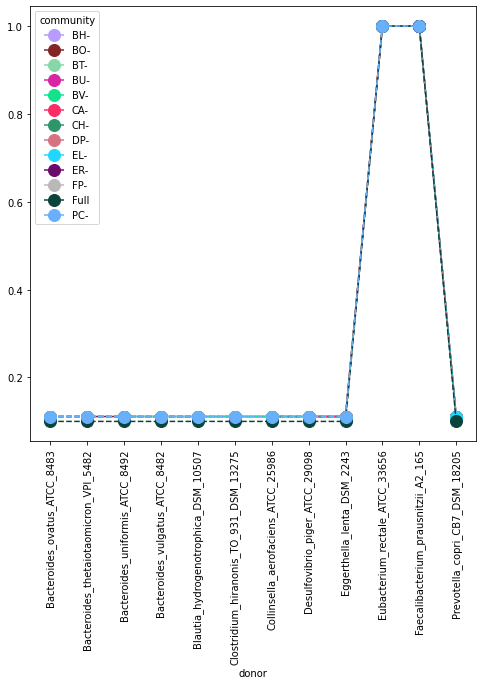

In [ ]:
gut_detailed_member_plot = gut_detailed_member[["community","donor","scs"]].groupby(["community","donor"]).mean()["scs"]\
                    .unstack()\
                    .sort_index().T\
                    #.fillna(0)
                    

ax = gut_detailed_member_plot.plot(rot=90,
                                  figsize=(8,8),
                                  cmap=cmap,
                                  linestyle="--",
                                  marker="o",
                                  markersize=12)

ax.set_xticks(np.arange(len(gut_detailed_member_plot.index)))
labels = ax.set_xticklabels(gut_detailed_member_plot.index)

# SteadyCom

**Load m9 media compounds**

*For E. coli mutants (M9 medium to force growth of specific members)*

In [151]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = list(media_db[media_db.medium=="M9"].compound.values)
m9_ecoli = ["M_"+met+"_e" for met in compounds]
m9_gut = ["M_"+met+"__91__e__93__" for met in compounds]

**Load data**

*E.coli mutants*

In [152]:
growth_ecoli = pd.read_csv("../output/Guillen2021/steadycom/growth.tsv",sep="\t",index_col=0)
relative_abundance_ecoli = pd.read_csv("../output/Guillen2021/steadycom/relative_abundance.tsv",sep="\t",index_col=0)
cross_feeding_ecoli = pd.read_csv("../output/Guillen2021/steadycom/cross_feeding.tsv",sep="\t")

cross_feeding_ecoli = cross_feeding_ecoli[~cross_feeding_ecoli.compound.isin(m9_ecoli)]

*Gut microbiome*

In [153]:
growth_gut = pd.read_csv("../output/Venturelli2018/steadycom/growth.tsv",sep="\t",index_col=0)
relative_abundance_gut = pd.read_csv("../output/Venturelli2018/steadycom/relative_abundance.tsv",sep="\t",index_col=0)
cross_feeding_gut = pd.read_csv("../output/Venturelli2018/steadycom/cross_feeding.tsv",sep="\t")

cross_feeding_gut = cross_feeding_gut[~cross_feeding_gut.compound.isin(m9_gut)]

### E. coli mutants

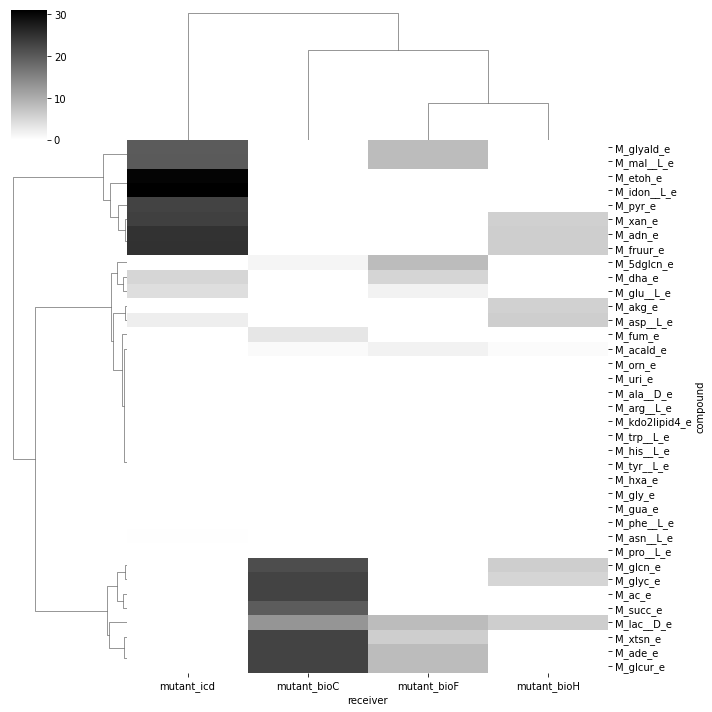

In [154]:
receivers_ecoli = cross_feeding_ecoli[cross_feeding_ecoli["rate?"]>1e-5]
receivers_ecoli = receivers_ecoli.dropna().groupby(["receiver","compound"]).sum()["rate?"]\
                    .unstack().fillna(0)

sns.clustermap(receivers_ecoli.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               method="ward")

<Axes: xlabel='receiver', ylabel='donor'>

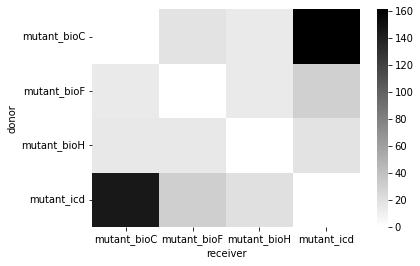

In [155]:
receivers_ecoli = cross_feeding_ecoli[cross_feeding_ecoli["rate?"]>1e-5]
receivers_ecoli = receivers_ecoli.dropna().groupby(["receiver","donor"]).sum()["rate?"]\
                    .unstack().fillna(0)
receivers_ecoli = receivers_ecoli.sort_index().T.sort_index().T
sns.heatmap(receivers_ecoli.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               )

### Gut microbiome

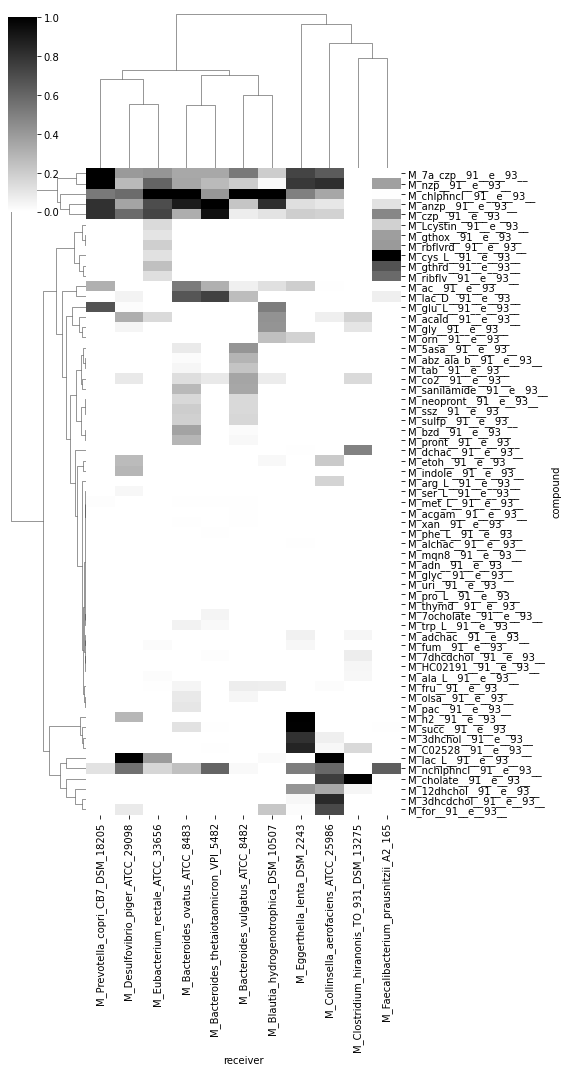

In [156]:
receivers_gut = cross_feeding_gut[cross_feeding_gut["rate?"]>1e-5]
receivers_gut = receivers_gut.dropna().groupby(["receiver","compound"]).sum()["rate?"]\
                    .unstack().fillna(0)

sns.clustermap(receivers_gut.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               method="ward",
               figsize=(8,15),
               standard_scale=1)

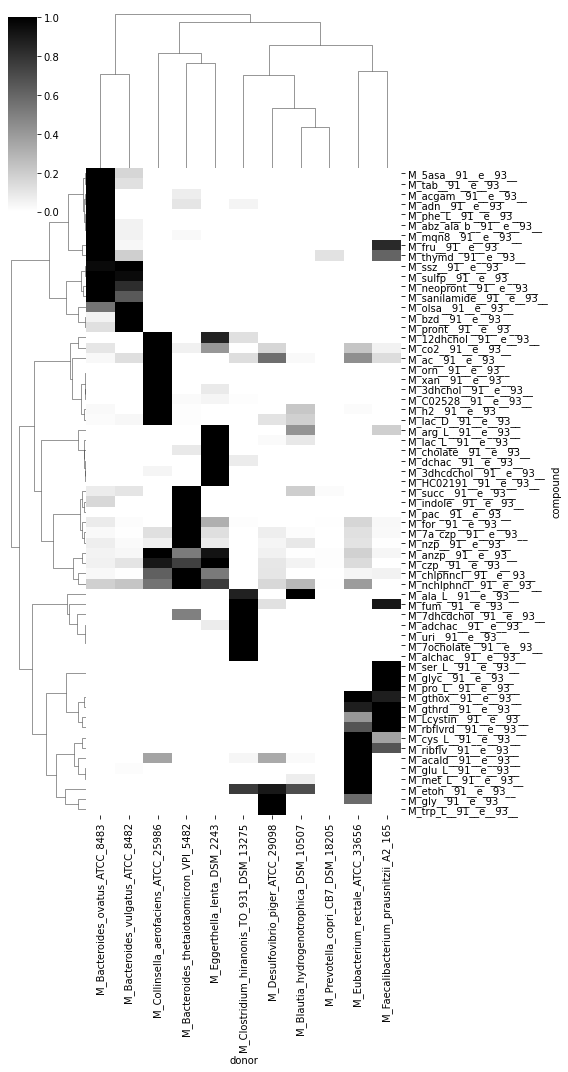

In [157]:
donor_gut = cross_feeding_gut[cross_feeding_gut["rate?"]>1e-5]
donor_gut = donor_gut.dropna().groupby(["donor","compound"]).sum()["rate?"]\
                    .unstack().fillna(0)

sns.clustermap(donor_gut.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               method="ward",
               figsize=(8,15),
               standard_scale=0)

<Axes: xlabel='receiver', ylabel='donor'>

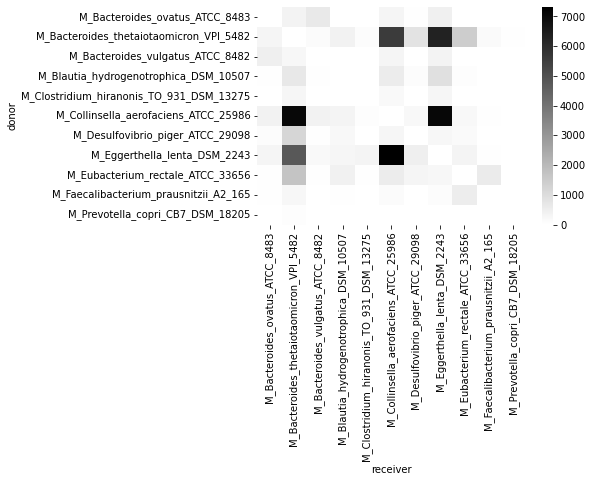

In [158]:
receivers_gut = cross_feeding_gut[cross_feeding_gut["rate?"]>1e-5]
receivers_gut = receivers_gut.dropna().groupby(["receiver","donor"]).sum()["rate?"]\
                    .unstack().fillna(0)

receivers_gut = receivers_gut.sort_index().T.sort_index().T
sns.heatmap(receivers_gut.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               #method="ward"
              )

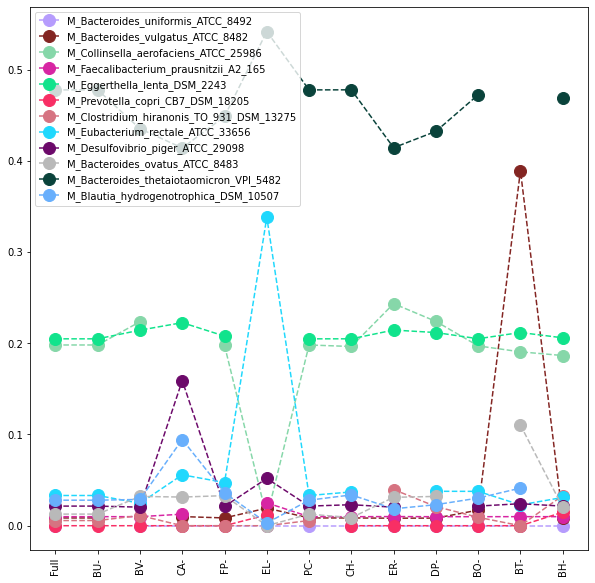

In [169]:
ax = relative_abundance_gut.T.plot(rot=90,
                            marker="o",
                            markersize=12,
                            linestyle="--",
                            figsize=(10,10),
                             cmap=cmap)

ax.set_xticks(np.arange(len(relative_abundance_gut.T.index)))
labels = ax.set_xticklabels(relative_abundance_gut.T.index)